# Chapter 1 — TD-PINNs: Collocation Strategy Comparison (Diffusion)

**Case:** 1-D linear diffusion / heat equation on $[0, 2\pi]$,

$$\frac{\partial u}{\partial t} = \nu\,\frac{\partial^2 u}{\partial x^2}.$$

**Source of truth — heat kernel.** A Gaussian initial condition stays Gaussian under diffusion (it is
the convolution of the IC with the heat kernel $G(x,t)=\frac{1}{\sqrt{4\pi\nu t}}e^{-x^2/4\nu t}$):

$$u(x,0)=e^{-(x-x_c)^2/2\sigma_0^2} \;\Longrightarrow\; u(x,t)=\frac{\sigma_0}{\sqrt{\sigma_0^2+2\nu t}}\,
\exp\!\Big(-\frac{(x-x_c)^2}{2(\sigma_0^2+2\nu t)}\Big).$$

**Goal:** identical experiment to the Burgers notebook — fixed scheme (**native `PINTrainer`**, TD-PINNs /
**Crank–Nicolson**, MLP) and vary *only* the collocation strategy — but on this linear diffusion problem
with the heat-kernel solution as ground truth. The summary reports **three error norms** ($L_1$, $L_2$,
$L_\infty$) as **(epochs, error) point plots**, saved to `figs/` as a PDF.

In [9]:
import sys, os, time

ROOT = '/home/df.gomezb/Tesis'
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from pinns_framework import (
    PINArchitecture, PINSpatialDimension, PINLossFunction, PINTrainer,
    compute_metrics,
    collocation_uniform, collocation_lhs, collocation_gradient,
    collocation_curvature, collocation_last_residual, collocation_mean_residual,
)

torch.manual_seed(0)
np.random.seed(0)
print('torch:', torch.__version__)

torch: 2.12.1+cu130


## 1. Problem setup — heat-kernel analytic solution

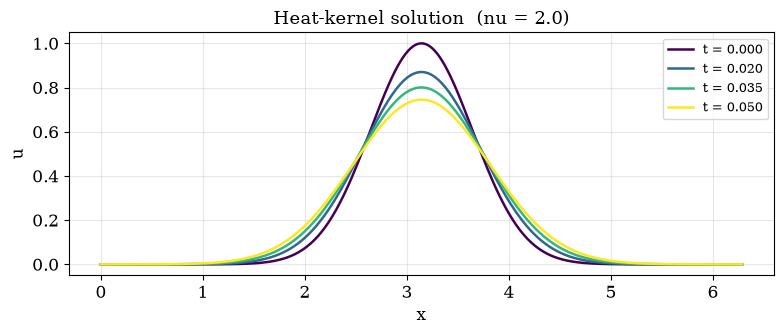

In [ ]:
NU     = 2.0                 # diffusivity
X0, XF = 0.0, 2 * np.pi
X_C    = np.pi               # initial Gaussian centre
S0     = 0.5                 # initial Gaussian width

def heat_kernel(t, x):
    """Exact diffusion of a Gaussian IC (heat-kernel convolution)."""
    x   = np.asarray(x, dtype=float)
    var = S0**2 + 2 * NU * t
    return (S0 / np.sqrt(var)) * np.exp(-(x - X_C)**2 / (2 * var))

x_plot = np.linspace(X0, XF, 500)
fig, ax = plt.subplots(figsize=(8, 3.5))
cmap = plt.cm.viridis
for i, t in enumerate([0.0, 0.02, 0.035, 0.05]):
    ax.plot(x_plot, heat_kernel(t, x_plot), color=cmap(i / 3), lw=1.8, label=f't = {t:.3f}')
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title(f'Heat-kernel solution  (nu = {NU})')
ax.legend(loc='upper right'); ax.grid(alpha=0.3)
plt.tight_layout(); 
FIGDIR = 'figs'
savepath = os.path.join(FIGDIR, 'diffussion_heat_kernel.pdf')
fig.savefig(savepath, bbox_inches='tight')
print('saved ->', savepath)
plt.show()

## 2. Experiment configuration

Same hyper-parameters as the Burgers notebook; only the PDE / exact solution differ.

In [11]:
ARCH        = 'MLP'
PARAMS_ARCH = {'layers': (1, 32, 32, 32, 1), 'activation': 'tanh'}

DT     = 0.01
T_END  = 0.05
NT     = round(T_END / DT)

EPOCHS     = 100000        # per-step budget / cap
TOLERANCE  = 1e-3          # absolute-loss early-stop threshold
LR         = 1e-2
MAX_LR     = 1e-2          # peak / initial lr (scheduler starts here)
MIN_LR     = 1e-6          # scheduler decay floor (ReduceLROnPlateau)
IC_WEIGHT  = 15.0/( (15**2+5**2+1**2)**(1/2) )
BC_WEIGHT  = 5.0/( (15**2+5**2+1**2)**(1/2) )
PDE_WEIGHT = 1.0/( (15**2+5**2+1**2)**(1/2) )
N_COLLOC   = 500
N_EVAL     = 1000

STRATEGIES = {
    'uniform'       : collocation_uniform,
    'lhs'           : collocation_lhs,
    'gradient'      : collocation_gradient,
    'curvature'     : collocation_curvature,
    'last_residual' : collocation_last_residual,
    'mean_residual' : collocation_mean_residual,
}

times = [k * DT for k in range(NT + 1)]
print(f'{NT} PDE steps of dt={DT}  ->  T={T_END}   |   {len(STRATEGIES)} strategies')

5 PDE steps of dt=0.01  ->  T=0.05   |   6 strategies


## 3. IC / BC, residual, exact-solution evaluator

The integrator is **Crank–Nicolson** with the diffusion operator $S(w) = -\nu\,w_{xx}$, so the residual
is $\frac{u-u^{t-1}}{\Delta t} + \tfrac12[S(u) + S(u^{t-1})]$. The Gaussian decays to $\approx 0$ at the
domain edges, so the boundary values are taken as $0$.

In [12]:
x_ic_np = np.linspace(X0, XF, 201)
u_ic_np = heat_kernel(0, x_ic_np)
x_ic = torch.tensor(x_ic_np, dtype=torch.float32).unsqueeze(1)
u_ic = torch.tensor(u_ic_np, dtype=torch.float32).unsqueeze(1)

x_bc = torch.tensor([[X0], [XF]], dtype=torch.float32)
u_bc = torch.tensor([[float(heat_kernel(0, X0))], [float(heat_kernel(0, XF))]], dtype=torch.float32)
print(f'IC range: [{u_ic.min():.3f}, {u_ic.max():.3f}]   BC values ~ {u_bc.ravel().tolist()}')

x_dim = PINSpatialDimension('x', domain=(X0, XF), n_colloc=N_COLLOC)

def heat_residual(u, u_prev, x, dt, nu):
    """Crank-Nicolson residual for the heat equation.  S(w) = -nu*w_xx."""
    def S(w):
        w_x  = torch.autograd.grad(w.sum(),   x, create_graph=True)[0]
        w_xx = torch.autograd.grad(w_x.sum(), x, create_graph=True)[0]
        return -nu * w_xx
    return (u - u_prev.detach()) / dt + 0.5 * (S(u) + S(u_prev).detach())

loss_fn = PINLossFunction([x_dim], heat_residual)

def exact_fn(t, x_pts):
    u = heat_kernel(t, x_pts.detach().cpu().numpy().ravel())
    return torch.tensor(u, dtype=torch.float32, device=x_pts.device).unsqueeze(1)

IC range: [0.000, 1.000]   BC values ~ [2.6752879911384753e-09, 2.6752879911384753e-09]


## 4. Run every strategy with the native `PINTrainer`

`compute_metrics` returns $L_2$ and $L_\infty$; we add the $L_1$ (mean-absolute) error per time level so
all three norms are available.

In [13]:
records = {}

for name, fn in STRATEGIES.items():
    torch.manual_seed(0); np.random.seed(0)
    net = PINArchitecture(ARCH, PARAMS_ARCH)
    trainer = PINTrainer(
        net=net, scheme='TD-PINNS', loss_fn=loss_fn, spatial_dims=[x_dim],
        epochs=EPOCHS, dt=DT, lr=LR, max_lr=MAX_LR, min_lr=MIN_LR, tolerance=TOLERANCE,
        ic_weight=IC_WEIGHT, bc_weight=BC_WEIGHT, pde_weight=PDE_WEIGHT,
        collocation_fn=fn, verbose=True, log_every=10000,
    )
    t0 = time.perf_counter()
    nets = trainer.fit(x_ic=x_ic, u_ic=u_ic, x_bc=x_bc, u_bc=u_bc, T=T_END, nu=NU)
    wall = time.perf_counter() - t0

    pde_steps = trainer.step_history[1:]
    epochs_used = sum(h['epochs'] for h in pde_steps)
    n_converged = sum(h['converged'] for h in pde_steps)
    df = compute_metrics(nets, times, [x_dim], n_eval=N_EVAL,
                         exact_fn=exact_fn, device=trainer.device)

    # compute_metrics gives L2 / Linf only — add L1 (mean-abs error) per level
    xg = torch.linspace(X0, XF, N_EVAL).unsqueeze(1).to(trainer.device)
    l1 = []
    for t, net_t in zip(times, nets):
        net_t.eval()
        with torch.no_grad():
            up = net_t(xg)
            if up.dim() == 1:
                up = up.unsqueeze(1)
        l1.append(float((up - exact_fn(t, xg)).abs().mean()))
    df['L1'] = l1

    records[name] = {
        'epochs_used'  : epochs_used,
        'all_converged': n_converged == len(pde_steps),
        'n_converged'  : n_converged,
        'n_steps'      : len(pde_steps),
        'mean_L1'      : float(df['L1'].mean()),
        'mean_L2'      : float(df['L2'].mean()),
        'mean_Linf'    : float(df['Linf'].mean()),
        'final_L1'     : float(df['L1'].iloc[-1]),
        'final_L2'     : float(df['L2'].iloc[-1]),
        'final_Linf'   : float(df['Linf'].iloc[-1]),
        'L1_series'    : df['L1'],
        'L2_series'    : df['L2'],
        'Linf_series'  : df['Linf'],
        'wall_s'       : wall,
        'nets'         : nets,
        'device'       : trainer.device,
    }
    print(f'{name:14s} | epochs {epochs_used:6d} | conv {n_converged}/{len(pde_steps)} '
          f'| L1 {df["L1"].mean():.3e} | L2 {df["L2"].mean():.3e} | Linf {df["Linf"].mean():.3e} '
          f'| wall {wall:5.1f}s')

=== TD-PINNs | step 0 — initial condition ===
  [step 0 / IC] converged at epoch 222 | loss 9.6207e-04
=== TD-PINNs | step 1/5  (t = 0.01) ===
  [step 1] converged at epoch 2033 | loss 9.8815e-04
=== TD-PINNs | step 2/5  (t = 0.02) ===
  [step 2] converged at epoch 1357 | loss 9.7749e-04
=== TD-PINNs | step 3/5  (t = 0.03) ===
  [step 3] converged at epoch 2212 | loss 9.9174e-04
=== TD-PINNs | step 4/5  (t = 0.04) ===
  [step 4] converged at epoch 1765 | loss 9.5525e-04
=== TD-PINNs | step 5/5  (t = 0.05) ===
  [step 5] converged at epoch 1110 | loss 9.9480e-04
uniform        | epochs   8477 | conv 5/5 | L1 1.531e-02 | L2 2.030e-02 | Linf 4.722e-02 | wall  18.2s
=== TD-PINNs | step 0 — initial condition ===
  [step 0 / IC] converged at epoch 222 | loss 9.6207e-04
=== TD-PINNs | step 1/5  (t = 0.01) ===
  [step 1] converged at epoch 2608 | loss 9.9775e-04
=== TD-PINNs | step 2/5  (t = 0.02) ===
  [step 2] converged at epoch 2272 | loss 9.9988e-04
=== TD-PINNs | step 3/5  (t = 0.03) ===


## 5. (epochs, error) — one point per strategy, for $L_1$, $L_2$, $L_\infty$

Three panels (one per norm), same plot convention: one marker per strategy (see the bottom table),
filled when all steps converged / hollow when capped. Saved to `figs/` as a PDF and shown inline.

saved -> figs/collocation_diffusion_epochs_norms.pdf


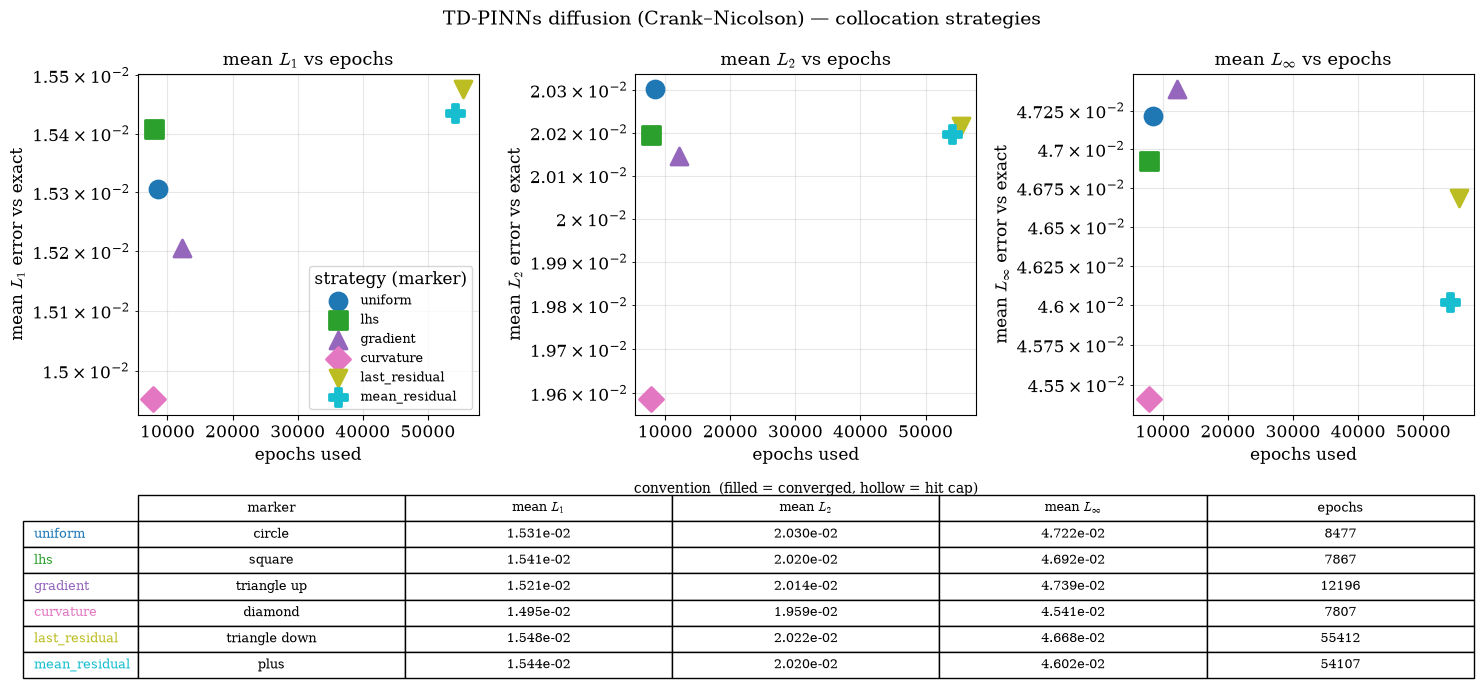

In [14]:
plt.rcParams.update({
    'font.family'     : 'serif',
    'font.serif'      : ['DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'font.size'       : 12,
    'axes.titlesize'  : 13,
    'axes.labelsize'  : 12,
    'legend.fontsize' : 9,
})

MARKERS = {
    'uniform'       : ('o', 'circle'),
    'lhs'           : ('s', 'square'),
    'gradient'      : ('^', 'triangle up'),
    'curvature'     : ('D', 'diamond'),
    'last_residual' : ('v', 'triangle down'),
    'mean_residual' : ('P', 'plus'),
}
colors   = plt.cm.tab10(np.linspace(0, 1, len(MARKERS)))
color_of = {name: colors[i] for i, name in enumerate(MARKERS)}

FIGDIR = 'figs'
os.makedirs(FIGDIR, exist_ok=True)

NORMS = [(r'$L_1$', 'mean_L1'), (r'$L_2$', 'mean_L2'), (r'$L_\infty$', 'mean_Linf')]

fig = plt.figure(figsize=(15, 7))
gs  = gridspec.GridSpec(2, 3, height_ratios=[3, 1.5], figure=fig)

for j, (label, key) in enumerate(NORMS):
    ax = fig.add_subplot(gs[0, j])
    for name, r in records.items():
        mk, _ = MARKERS[name]
        c     = color_of[name]
        face  = c if r['all_converged'] else 'none'
        ax.scatter(r['epochs_used'], r[key], s=150, marker=mk, color=c, facecolors=face,
                   edgecolors=c, linewidths=2, zorder=3, label=name)
    ax.set_yscale('log')
    ax.set_xlabel('epochs used')
    ax.set_ylabel(f'mean {label} error vs exact')
    ax.set_title(f'mean {label} vs epochs')
    ax.grid(True, which='both', alpha=0.3)
    if j == 0:
        ax.legend(title='strategy (marker)', loc='best')

# ── convention + results table (all three norms) ─────────────────────────
ax_tab = fig.add_subplot(gs[1, :]); ax_tab.axis('off')
rows = [n for n in MARKERS if n in records]
cell_text = [[MARKERS[n][1],
              f"{records[n]['mean_L1']:.3e}", f"{records[n]['mean_L2']:.3e}",
              f"{records[n]['mean_Linf']:.3e}", f"{records[n]['epochs_used']}"]
             for n in rows]
tbl = ax_tab.table(cellText=cell_text, rowLabels=rows,
                   colLabels=['marker', r'mean $L_1$', r'mean $L_2$', r'mean $L_\infty$', 'epochs'],
                   loc='center', cellLoc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.5)
for i, n in enumerate(rows):
    tbl[(i + 1, -1)].get_text().set_color(color_of[n])
ax_tab.set_title('convention  (filled = converged, hollow = hit cap)', fontsize=10)

fig.suptitle('TD-PINNs diffusion (Crank–Nicolson) — collocation strategies', fontsize=14)
plt.tight_layout()
savepath = os.path.join(FIGDIR, 'collocation_diffusion_epochs_norms.pdf')
fig.savefig(savepath, bbox_inches='tight')
print('saved ->', savepath)
plt.show()

## 6. Summary table, per-level errors, and solution overlay

In [15]:
summary = pd.DataFrame([
    {'strategy': n, 'epochs_used': r['epochs_used'],
     'converged': f"{r['n_converged']}/{r['n_steps']}",
     'mean_L1': r['mean_L1'], 'mean_L2': r['mean_L2'], 'mean_Linf': r['mean_Linf'],
     'final_L1': r['final_L1'], 'final_L2': r['final_L2'], 'final_Linf': r['final_Linf'],
     'wall_s': r['wall_s']}
    for n, r in records.items()
]).set_index('strategy').sort_values('mean_Linf')
pd.set_option('display.float_format', '{:.4e}'.format)
print('=== Collocation strategy summary (diffusion, sorted by mean Linf) ===')
print(summary.to_string())
print(f'\nBest mean Linf: {summary.index[0]}')

=== Collocation strategy summary (diffusion, sorted by mean Linf) ===
               epochs_used converged    mean_L1    mean_L2  mean_Linf   final_L1   final_L2  final_Linf     wall_s
strategy                                                                                                          
curvature             7807       5/5 1.4952e-02 1.9586e-02 4.5407e-02 1.0383e-02 1.3857e-02  3.2316e-02 2.0832e+01
mean_residual        54107       5/5 1.5436e-02 2.0198e-02 4.6023e-02 1.0868e-02 1.4601e-02  3.3264e-02 1.2194e+02
last_residual        55412       5/5 1.5476e-02 2.0216e-02 4.6684e-02 1.1122e-02 1.4788e-02  3.5214e-02 1.2688e+02
lhs                   7867       5/5 1.5408e-02 2.0195e-02 4.6921e-02 1.0956e-02 1.4647e-02  3.4900e-02 1.8719e+01
uniform               8477       5/5 1.5305e-02 2.0302e-02 4.7215e-02 1.0831e-02 1.5256e-02  3.6478e-02 1.8166e+01
gradient             12196       5/5 1.5206e-02 2.0145e-02 4.7391e-02 1.0957e-02 1.5217e-02  3.7913e-02 3.2236e+01

Best mean

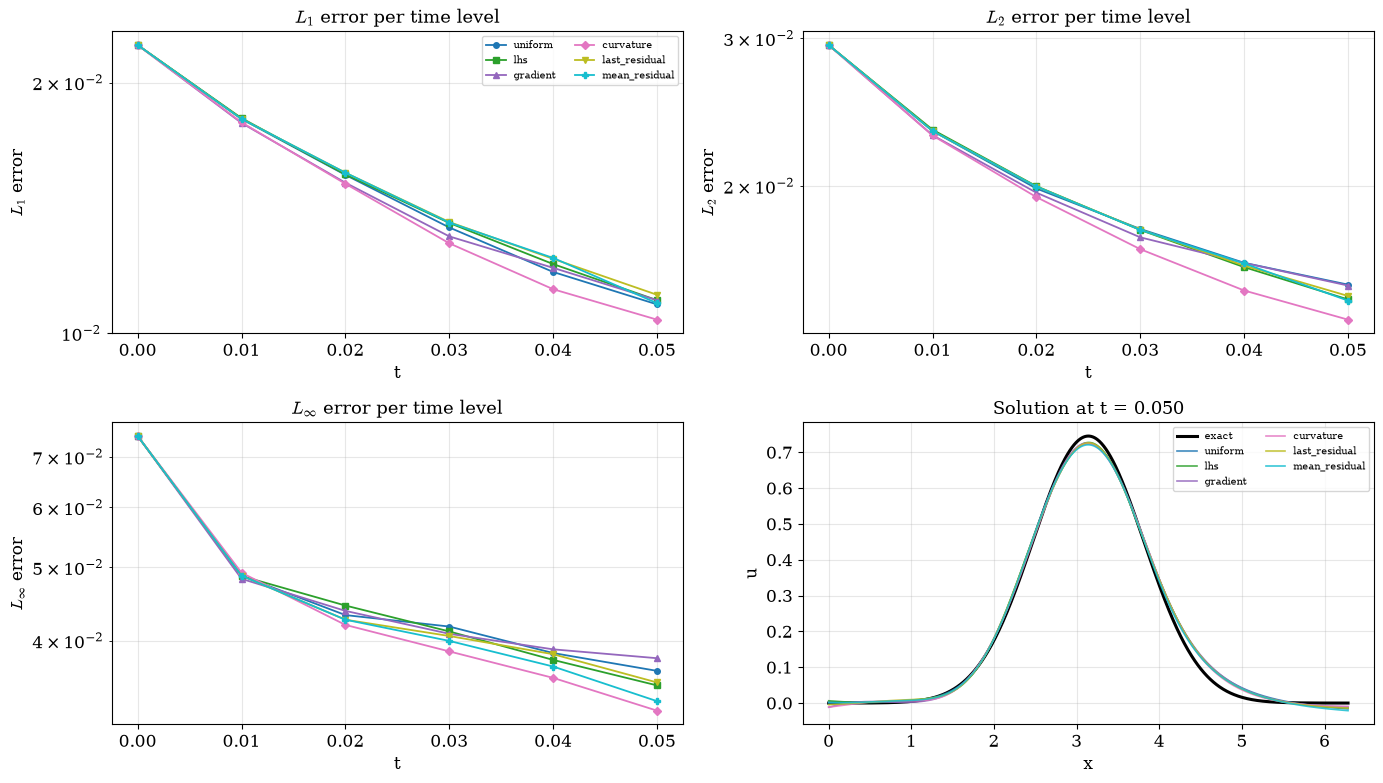

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.ravel()

for ax, (label, skey) in zip(axes[:3],
                             [(r'$L_1$', 'L1_series'), (r'$L_2$', 'L2_series'), (r'$L_\infty$', 'Linf_series')]):
    for name, r in records.items():
        ax.semilogy(times, r[skey].values, '-', lw=1.3, ms=4,
                    color=color_of[name], marker=MARKERS[name][0], label=name)
    ax.set_xlabel('t'); ax.set_ylabel(f'{label} error')
    ax.set_title(f'{label} error per time level')
    ax.grid(True, which='both', alpha=0.3)
axes[0].legend(ncol=2, fontsize=7)

# solution overlay at final time
ax = axes[3]
x_eval = torch.linspace(X0, XF, N_EVAL).unsqueeze(1)
xev_np = x_eval.numpy().ravel()
ax.plot(xev_np, heat_kernel(T_END, xev_np), 'k-', lw=2.2, label='exact')
for name, r in records.items():
    net = r['nets'][-1].eval()
    with torch.no_grad():
        u = net(x_eval.to(r['device'])).cpu().numpy().ravel()
    ax.plot(xev_np, u, lw=1.2, color=color_of[name], alpha=0.85, label=name)
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title(f'Solution at t = {T_END:.3f}')
ax.legend(ncol=2, fontsize=7); ax.grid(alpha=0.3)
savepath = os.path.join(FIGDIR, 'collocation_diffusion_errors.pdf')
fig.savefig(savepath, bbox_inches='tight')
plt.tight_layout(); plt.show()

## 7. Notes

- Identical methodology to the Burgers collocation notebook (native `PINTrainer`, Crank–Nicolson,
  `max_lr`/`min_lr` schedule, `step_history` for epochs) — only the PDE and the exact solution change.
- Ground truth is the **heat kernel**: an analytic diffusing Gaussian, so the errors are exact.
- Three norms are reported: $L_1$ (mean-abs), $L_2$ (RMS), $L_\infty$ (max). `compute_metrics` supplies
  $L_2$ and $L_\infty$; $L_1$ is added in the run cell.
- Figure saved to `figs/collocation_diffusion_epochs_norms.pdf`; the marker convention matches the
  Burgers notebook so the point plots can be compared side by side.